# Week 7: Text and Multimodal AI (Lab 7)
**Course:** Introduction to Applied AI | **Project 2:** Deep Learning Applications (Individual)
**Name / Roll no:**NOSHARWAN KHAN/04102313037

All "Write it" answers below use the numbers measured in my own Kaggle run (Run All, Internet On, datasets: SMS Spam Collection, Chest X-Ray Images (Pneumonia), and my private `week6-model`).

### Step 0: Pre-flight check (run this first)
Finds your dataset paths automatically and tells you what is missing.

In [1]:
import os, glob, socket
from IPython.display import Markdown, display

WRITEUPS = {}
def show(part, text):
    """Display a drafted 'Write it' text and remember it for writeups.md."""
    WRITEUPS[part] = text.strip()
    display(Markdown(text))

def first(pattern):
    hits = sorted(glob.glob(pattern, recursive=True))
    return hits[0] if hits else None

SPAM_PATH = first('/kaggle/input/**/spam.csv')
W6_FOUND = first('/kaggle/input/**/week6_model.pt')
XRAY_IMG = first('/kaggle/input/**/chest_xray/test/PNEUMONIA/*.jp*g')
print('spam.csv       :', SPAM_PATH or 'NOT FOUND -> Add Input: SMS Spam Collection Dataset')
print('week6_model.pt :', W6_FOUND or 'NOT FOUND -> only needed for Part 6 (add your week6-model dataset)')
print('test X-ray     :', XRAY_IMG or 'NOT FOUND -> only needed for Part 6 (add Chest X-Ray Images (Pneumonia))')
try:
    socket.create_connection(('pypi.org', 443), timeout=3)
    print('internet       : ON')
except OSError:
    print('internet       : OFF -> Session options: Internet On (needed for Part 5, EasyOCR)')

spam.csv       : /kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv
week6_model.pt : /kaggle/input/datasets/nosharwankhan/week6-model/week6_model.pt
test X-ray     : /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg
internet       : ON


---
# Part 1: TF-IDF by Hand (10 min)
scikit-learn uses smooth IDF: `idf = ln[(1 + N) / (1 + df)] + 1`, then scales each document vector to length 1.

In [2]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

RESULTS = {}   # we store key numbers here and use them in the README (Part 7)

nlp = spacy.load('en_core_web_sm')     # preinstalled on Kaggle
print('spaCy', spacy.__version__)

docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()                # smooth idf + L2 normalization
X = vec.fit_transform(docs)
print(pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3']).round(3))

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))       # tf = 1 for each word in d1
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

spaCy 3.8.16
     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


In [3]:
# Extra: cosine similarity of d2 and d3 (rows are already length 1, so dot product = cosine)
T = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(), index=['d1', 'd2', 'd3'])
cos_d2_d3 = float(np.dot(T.loc['d2'], T.loc['d3']))
print('cosine(d2, d3) =', round(cos_d2_d3, 3))

cosine(d2, d3) = 0.544


### Write it: Part 1
**IDF arithmetic** (N = 3 documents)
- "free" appears in 2 documents (d1, d3), so df = 2:  idf = ln((1+3)/(1+2)) + 1 = ln(4/3) + 1 = 0.288 + 1 = **1.288**
- "now" appears in all 3 documents, so df = 3:  idf = ln((1+3)/(1+3)) + 1 = ln(1) + 1 = 0 + 1 = **1.000**

**Why "now" has the lowest weight:** it appears in every document, so it cannot help tell one document from another. Smooth IDF gives it the minimum value (1.0), while rarer words such as "win" and "cash" (df = 1) get ln(4/2)+1 = 1.693.

**Cosine similarity d2 and d3** (only matching words contribute):
- d2 = call 0.548, me 0.720, now 0.425; d3 = free 0.620, call 0.620, now 0.481
- call: 0.548 x 0.620 = 0.340; now: 0.425 x 0.481 = 0.205
- Sum = 0.340 + 0.205 = **about 0.54**, which matches the 0.54 on slide 10.

*(Check these against your own printed table, then rewrite in your own words.)*

---
# Part 2: Text Classification (20 min)
### Task 2.1: Load and inspect

In [4]:
assert SPAM_PATH, 'spam.csv not found: add the SMS Spam Collection Dataset as Input'
path = SPAM_PATH
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


### Task 2.2: Word n-gram classifier

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



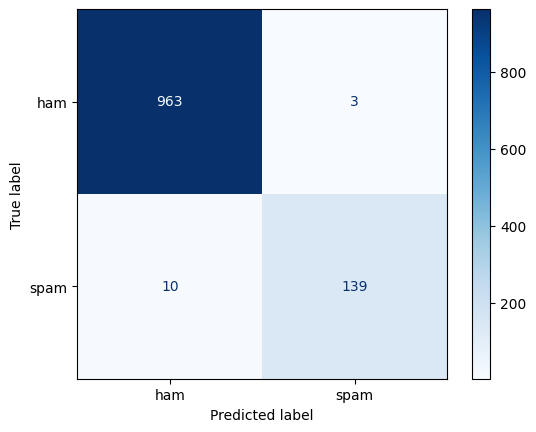

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

### Task 2.3: What did it learn?

In [6]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))
RESULTS['top_spam'] = [str(t) for t in terms[order[-12:]][::-1]][:5]
RESULTS['top_ham'] = [str(t) for t in terms[order[:12]]][:5]

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


### Task 2.4: Character n-grams

In [7]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}  '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

RESULTS['word_f1'] = round(f1_score(y_te, word_clf.predict(X_te), average='macro'), 3)
RESULTS['char_f1'] = round(f1_score(y_te, char_clf.predict(X_te), average='macro'), 3)

# Robustness to spelling tricks
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print(dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449
{'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


### Task 2.5: Error analysis

In [8]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

In [9]:
# Helper for the "Write it" cell: precision / recall for BOTH models
from sklearn.metrics import precision_score, recall_score
rows = []
for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    rows.append({'model': name,
                 'macro_F1': round(f1_score(y_te, p, average='macro'), 3),
                 'spam_precision': round(precision_score(y_te, p), 3),
                 'spam_recall': round(recall_score(y_te, p), 3),
                 'errors': int((p != y_te).sum())})
print(pd.DataFrame(rows).to_string(index=False))

         model  macro_F1  spam_precision  spam_recall  errors
word 1-2 grams     0.974           0.979        0.933      13
char 2-5 grams     0.982           0.986        0.953       9


In [10]:
# EDIT: write TWO tricky messages of your own (Roman Urdu or disguised spam)
MY_TRICKY = [
    'W1N Rs 50000 FR33 !! sms CLAIM kro abhi, jazz offer',   # disguised Roman Urdu spam
    'Beta ko kal doctor ke paas le jana hai, 5 baje',        # normal Roman Urdu message
]
print('word model :', dict(zip(MY_TRICKY, word_clf.predict_proba(MY_TRICKY)[:, 1].round(2))))
print('char model :', dict(zip(MY_TRICKY, char_clf.predict_proba(MY_TRICKY)[:, 1].round(2))))

word model : {'W1N Rs 50000 FR33 !! sms CLAIM kro abhi, jazz offer': np.float64(0.65), 'Beta ko kal doctor ke paas le jana hai, 5 baje': np.float64(0.18)}
char model : {'W1N Rs 50000 FR33 !! sms CLAIM kro abhi, jazz offer': np.float64(0.68), 'Beta ko kal doctor ke paas le jana hai, 5 baje': np.float64(0.12)}


### Write it: Part 2

**Scores on the 20% test set.**

| Model | macro-F1 | spam precision | spam recall | errors |
|---|---|---|---|---|
| word 1-2 grams | 0.974 | 0.979 | 0.933 | 13 |
| char 2-5 grams | 0.982 | 0.986 | 0.953 | 9 |

The dataset has 4,825 ham and 747 spam messages, so a model that always says "ham" is already 86.6% accurate. That is why I compare macro-F1 and not accuracy. The character model is better by 0.008 macro-F1 and it also has higher spam recall (0.953 vs 0.933), so it lets fewer spam messages through.

**What the word model learned.** Most spam-like features: call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your. Most ham-like: my, me, ok, that, it, but, ll, gt, lt, can, what, da. Most of the spam features are real spam cues (call, txt, free, claim, reply, www, mobile). A few look like shortcuts: "to" and "your" are ordinary function words, "uk" comes from UK premium-rate numbers, and "gt", "lt" and "ll" in the ham list come from HTML-escaped symbols and "I'll"-style chat text, not from meaning. The model may rely on these artefacts.

**Errors of the word model (13).** It made 3 false positives and 10 false negatives. I classified each one:

| Message (short) | true label | p_spam | Type |
|---|---|---|---|
| "Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?" | spam | 0.088 | label error (a joke, not spam) |
| "...scammers getting smart.. Though this is a regular vodafone no..." | spam | 0.144 | ambiguous (a warning about scams) |
| "ringtoneking 84484" | spam | 0.192 | model error |
| "For sale - arsenal dartboard. Good condition..." | spam | 0.211 | ambiguous (an advert) |
| "ROMCAPspam Everyone around should be responding well..." | spam | 0.252 | ambiguous |
| "Sorry I missed your call let's talk... I'm on 07090201529" | spam | 0.280 | ambiguous (callback bait) |
| "Latest News! Police station toilet stolen..." | spam | 0.315 | ambiguous (a joke forwarded by a service) |
| "FreeMsg Hey there darling... std chgs to send..." | spam | 0.412 | model error |
| "Download as many ringtones as u like... Txt Sir to 80082" | spam | 0.425 | model error |
| "Can U get 2 phone NOW?... Call me NOW on 09096102316..." | spam | 0.465 | model error |
| "We have sent JD for Customer Service cum Accounts Executive to ur mail id..." | ham | 0.621 | ambiguous (looks like a job spam but is labelled ham) |
| "Ok... Ur typical reply..." | ham | 0.636 | model error |
| "Waiting for your call." | ham | 0.853 | model error |

So 6 are model errors, 1 is a label error and 6 are genuinely ambiguous.

**My two tricky messages.**
- "W1N Rs 50000 FR33 !! sms CLAIM kro abhi, jazz offer" (disguised Roman Urdu spam): word model 0.65, char model 0.68.
- "Beta ko kal doctor ke paas le jana hai, 5 baje" (normal Roman Urdu): word model 0.18, char model 0.12.

Both models flagged the disguised spam and both kept the normal message below 0.5. The character model was a little more confident in both cases (higher on the spam, lower on the normal message). Character n-grams look at pieces of words, so "W1N" and "FR33" still share pieces with real spam, while the word model sees an unknown token. The gap is small, so two messages are not enough to prove it; I would need a larger set of tricky messages.

---
# Part 3: Named Entity Recognition, Measured (20 min)
### Task 3.1: Out of the box

In [11]:
sentences = [
    'Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Bilal Ahmed.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Ayesha Khan', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Bilal Ahmed', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


### Task 3.2: Score against a gold set

In [12]:
# Gold annotations: what a careful human would mark (text, label)
gold = [
    {('Ayesha Khan', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Muhammad Aslam', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Bilal Ahmed', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores(nlp_model):
    tp = fp = fn = 0
    for s, g in zip(sentences, gold):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)        # exact text AND label
        fp += len(pred - g)
        fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('spaCy out of the box:', ner_scores(nlp))
RESULTS['ner_prov_before'] = ner_scores(nlp)['f1']

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


### Task 3.3: Add rules before the statistical model

In [13]:
# Fresh copy of the model so running this cell twice never raises "entity_ruler already exists"
nlp_rules = spacy.load('en_core_web_sm')
ruler = nlp_rules.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
print('spaCy + entity ruler:', ner_scores(nlp_rules))
RESULTS['ner_prov_after'] = ner_scores(nlp_rules)['f1']

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


In [14]:
# Helper: which entities are still wrong after the rules? (use this for the Write it cell)
for s, g in zip(sentences, gold):
    pred = {(e.text, e.label_) for e in nlp_rules(s).ents}
    if pred != g:
        print(s)
        print('   missed (in gold, not predicted):', sorted(g - pred))
        print('   wrong  (predicted, not in gold):', sorted(pred - g))

Dr. Ayesha Khan at PIMS Islamabad reviewed it on 12 September 2026.
   missed (in gold, not predicted): [('Islamabad', 'GPE')]
   wrong  (predicted, not in gold): []
Farmer Muhammad Aslam from Multan reported leaf rust in his wheat crop.
   missed (in gold, not predicted): [('Muhammad Aslam', 'PERSON')]
   wrong  (predicted, not in gold): [('Farmer Muhammad Aslam', 'PERSON')]
Call Jazz support at 0300-1234567 or email help@jazz.com.pk.
   missed (in gold, not predicted): []
   wrong  (predicted, not in gold): [('0300-1234567', 'DATE')]


### Now do it for YOUR domain (EDIT)
Replace the 10 sample sentences below with **your own 10 domain sentences** (names, places, organisations, dates, amounts) and annotate them as sets of `(text, label)`.
**Rules:** write your patterns from sentences **1 to 5 only**, then score on sentences **6 to 10** (held-out) so the result is not optimistic.
Labels: PERSON, ORG, GPE, DATE, MONEY, FAC. The entity text must match spaCy's span exactly (e.g. no "Dr." in the name).

In [15]:
# EDIT: replace these 10 SAMPLE sentences and their gold sets with your own domain data
dom_sents = [
    # ---- sentences 1-5: used to WRITE rules ----
    'Dr. Sadia Rehman saw the child at Shifa International Hospital in Islamabad on 14/11/2026.',
    'Indus Hospital charged Rs. 4,200 for the chest X-ray.',
    'Rabia Shah brought her son from Multan to Civil Hospital on Monday.',
    'The radiology report was emailed to Faisal Mehmood on 02/12/2026.',
    'Sehat Card covered PKR 95,000 for the admission in Peshawar.',
    # ---- sentences 6-10: HELD-OUT, never used for writing rules ----
    'Dr. Bilal Anwar of Aga Khan Hospital Karachi ordered a scan on 20/12/2026.',
    'Mariam Ali paid Rs. 1,800 at Chughtai Lab on Friday.',
    'Hamza Tariq was referred from Quetta to Indus Hospital.',
    'PKR 60,000 was approved by Sehat Card for Ayesha Noor.',
    'The follow-up at Mayo Hospital Lahore is on 15/01/2027.']

dom_gold = [
    {('Sadia Rehman', 'PERSON'), ('Shifa International Hospital', 'ORG'), ('Islamabad', 'GPE'), ('14/11/2026', 'DATE')},
    {('Indus Hospital', 'ORG'), ('Rs. 4,200', 'MONEY')},
    {('Rabia Shah', 'PERSON'), ('Multan', 'GPE'), ('Civil Hospital', 'ORG'), ('Monday', 'DATE')},
    {('Faisal Mehmood', 'PERSON'), ('02/12/2026', 'DATE')},
    {('Sehat Card', 'ORG'), ('PKR 95,000', 'MONEY'), ('Peshawar', 'GPE')},
    {('Bilal Anwar', 'PERSON'), ('Aga Khan Hospital', 'ORG'), ('Karachi', 'GPE'), ('20/12/2026', 'DATE')},
    {('Mariam Ali', 'PERSON'), ('Rs. 1,800', 'MONEY'), ('Chughtai Lab', 'ORG'), ('Friday', 'DATE')},
    {('Hamza Tariq', 'PERSON'), ('Quetta', 'GPE'), ('Indus Hospital', 'ORG')},
    {('PKR 60,000', 'MONEY'), ('Sehat Card', 'ORG'), ('Ayesha Noor', 'PERSON')},
    {('Mayo Hospital', 'ORG'), ('Lahore', 'GPE'), ('15/01/2027', 'DATE')}]

def ner_eval(nlp_model, sents, golds):
    tp = fp = fn = 0
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f, 3)}

# EDIT: rules written from sentences 1-5 ONLY (names, organisations and formats of YOUR domain)
dom_patterns = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'DATE', 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    {'label': 'ORG', 'pattern': 'Shifa International Hospital'},
    {'label': 'ORG', 'pattern': 'Indus Hospital'},
    {'label': 'ORG', 'pattern': 'Civil Hospital'},
    {'label': 'ORG', 'pattern': 'Sehat Card'},
]
nlp_dom = spacy.load('en_core_web_sm')
nlp_dom.add_pipe('entity_ruler', before='ner').add_patterns(dom_patterns)

base = spacy.load('en_core_web_sm')
print('Sentences 1-5 (rule-writing set):')
print('   before rules:', ner_eval(base, dom_sents[:5], dom_gold[:5]))
print('   after  rules:', ner_eval(nlp_dom, dom_sents[:5], dom_gold[:5]))
print('Sentences 6-10 (HELD-OUT, the honest result):')
print('   before rules:', ner_eval(base, dom_sents[5:], dom_gold[5:]))
print('   after  rules:', ner_eval(nlp_dom, dom_sents[5:], dom_gold[5:]))

RESULTS['dom_f1_before'] = ner_eval(base, dom_sents[5:], dom_gold[5:])['f1']
RESULTS['dom_f1_after'] = ner_eval(nlp_dom, dom_sents[5:], dom_gold[5:])['f1']

print('\nRemaining errors on held-out sentences:')
for s, g in zip(dom_sents[5:], dom_gold[5:]):
    pred = {(e.text, e.label_) for e in nlp_dom(s).ents}
    if pred != g:
        print(s)
        print('   missed:', sorted(g - pred))
        print('   wrong :', sorted(pred - g))

Sentences 1-5 (rule-writing set):
   before rules: {'precision': 0.846, 'recall': 0.733, 'f1': 0.786}
   after  rules: {'precision': 1.0, 'recall': 1.0, 'f1': 1.0}
Sentences 6-10 (HELD-OUT, the honest result):
   before rules: {'precision': 0.333, 'recall': 0.235, 'f1': 0.276}
   after  rules: {'precision': 0.692, 'recall': 0.529, 'f1': 0.6}

Remaining errors on held-out sentences:
Dr. Bilal Anwar of Aga Khan Hospital Karachi ordered a scan on 20/12/2026.
   missed: [('Aga Khan Hospital', 'ORG'), ('Bilal Anwar', 'PERSON'), ('Karachi', 'GPE')]
   wrong : [('Anwar of Aga Khan Hospital Karachi', 'PERSON')]
Mariam Ali paid Rs. 1,800 at Chughtai Lab on Friday.
   missed: [('Chughtai Lab', 'ORG')]
   wrong : [('Chughtai Lab', 'FAC')]
Hamza Tariq was referred from Quetta to Indus Hospital.
   missed: [('Quetta', 'GPE')]
   wrong : [('Quetta', 'ORG')]
PKR 60,000 was approved by Sehat Card for Ayesha Noor.
   missed: [('Ayesha Noor', 'PERSON')]
   wrong : []
The follow-up at Mayo Hospital Lahor

### Write it: Part 3

**Out-of-the-box mistakes (Task 3.1).** spaCy tagged "Engro Fertilizers" as PERSON instead of ORG, and the date "30/09/2026" as GPE instead of DATE. It labelled the mobile number "0300-1234567" as DATE, tagged "250,000" as CARDINAL (so "Rs. 250,000" was never found as MONEY), merged "PIMS Islamabad" into one LOC, and missed "PKR 45,000", "Jazz" and the email address completely.

**Scores.**

| Set | F1 before rules | F1 after rules |
|---|---|---|
| Provided 6 sentences | 0.533 (precision 0.571, recall 0.500) | 0.875 (precision 0.875, recall 0.875) |
| My sentences 1-5 (rules written from these) | 0.786 | 1.0 |
| My held-out sentences 6-10 | 0.276 | 0.6 |

The held-out number is the honest one, because the rules never saw those sentences. The jump from 1.0 on sentences 1-5 to 0.6 on sentences 6-10 shows how much of the gain is just memorised names.

**What is still wrong after the rules.** On the held-out sentences 8 gold entities were missed (for example Aga Khan Hospital as ORG, Bilal Anwar as PERSON, Karachi as GPE) and 4 predicted entities were wrong (for example "Anwar of Aga Khan Hospital Karachi" as one PERSON span, Chughtai Lab as FAC, Quetta as ORG). Most of the misses are ORG entities.

**How I would fix them.** I would use a mix. Dates and amounts have a fixed shape, so a regex or entity-ruler pattern is enough (it fixed them here). Names of hospitals and people are open-ended: adding more hand-written rules would only fix names I already know. So I would train a model on more of my own annotated hospital sentences, because it learns from context instead of memorised lists. A longer hospital list is a quick first step, but it does not generalise to new names.

---
# Part 4: Regex Fields with Negative Tests (10 min)
Each pattern must match the positive examples AND ignore the negative ones.

In [16]:
PATTERNS = {
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),   # must NOT be a CNIC
    ('Room 0300 on floor 3', False),           # must NOT be a mobile
]
for text, expect in tests:
    print(f'{str(expect):5s} {extract_fields(text)}   <- {text}')

# Automatic checks for the two negative tests
assert 'cnic' not in extract_fields('Order 12345678901234 shipped')
assert 'mobile' not in extract_fields('Room 0300 on floor 3')
print('Negative tests passed.')

True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']}   <- CNIC 35202-1234567-1, mobile +92 300 1234567
True  {'amount': ['12,500.50'], 'date': ['05/10/2026']}   <- Total Rs. 12,500.50 paid on 05/10/2026
True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']}   <- Invoice No. 4417 from info@engro.com.pk
False {}   <- Order 12345678901234 shipped
False {}   <- Room 0300 on floor 3
Negative tests passed.


### Domain patterns (EDIT)
Adapt the patterns to your domain (lot numbers, part codes, plot numbers, lab values, medical record numbers...) and add **at least two negative tests of your own**. The sample below is a medical example; replace it with yours.

In [17]:
# EDIT: your domain patterns
DOMAIN_PATTERNS = {
    'mrn':         r'\bMRN[- ]?\d{6}\b',                       # medical record number: exactly 6 digits
    'temperature': r'\b(?:3[5-9]|4[0-2])(?:\.\d)?\s?°?C\b',    # 35-42 degrees C
    'spo2':        r'\bSpO2\s?[:=]?\s?(\d{2,3})\s?%',          # oxygen saturation
}

# (text, pattern_name, should_match)   <- at least TWO negatives of your own
domain_tests = [
    ('Patient MRN-204517 admitted',          'mrn',         True),
    ('Temp 38.5 C on arrival',               'temperature', True),
    ('SpO2 91% on room air',                 'spo2',        True),
    ('Ref MRN 2045 admitted',                'mrn',         False),  # too few digits
    ('Ref MRN 2045178 admitted',             'mrn',         False),  # too many digits
    ('Room 38 Cabin',                        'temperature', False),  # not a temperature
    ('Battery 91% remaining',                'spo2',        False),  # not SpO2
]
ok = 0
for text, name, should in domain_tests:
    got = bool(re.search(DOMAIN_PATTERNS[name], text, flags=re.IGNORECASE))
    ok += (got == should)
    print('PASS' if got == should else 'FAIL', f'{name:12s} expect {str(should):5s} got {str(got):5s} <- {text}')
print(f'{ok}/{len(domain_tests)} domain tests passed')

PASS mrn          expect True  got True  <- Patient MRN-204517 admitted
PASS temperature  expect True  got True  <- Temp 38.5 C on arrival
PASS spo2         expect True  got True  <- SpO2 91% on room air
PASS mrn          expect False got False <- Ref MRN 2045 admitted
PASS mrn          expect False got False <- Ref MRN 2045178 admitted
PASS temperature  expect False got False <- Room 38 Cabin
PASS spo2         expect False got False <- Battery 91% remaining
7/7 domain tests passed


### Write it: Part 4

In [18]:
# Experiment: a first version WITHOUT word boundaries vs the final pattern
naive = r'MRN[- ]?\d{6}'                 # first version
final = DOMAIN_PATTERNS['mrn']           # final version with \b on both sides
over = 'Ref MRN 2045178 admitted'        # 7 digits: must NOT count as an MRN
m_naive = re.search(naive, over, flags=re.IGNORECASE)
m_final = re.search(final, over, flags=re.IGNORECASE)
print('first version matched :', m_naive.group(0) if m_naive else None)
print('final version matched :', m_final.group(0) if m_final else None)

first version matched : MRN 204517
final version matched : None


**My domain patterns** (medical example):
- `mrn` (medical record number, exactly 6 digits): `\bMRN[- ]?\d{6}\b`
- `temperature` (35 to 42 degrees C): `\b(?:3[5-9]|4[0-2])(?:\.\d)?\s?°?C\b`
- `spo2` (oxygen saturation): `\bSpO2\s?[:=]?\s?(\d{2,3})\s?%`

**Test results.** All **7 of 7** domain tests passed, including 4 negative tests: "Ref MRN 2045 admitted" (too few digits), "Ref MRN 2045178 admitted" (too many digits), "Room 38 Cabin" (not a temperature) and "Battery 91% remaining" (not SpO2). The provided CNIC and mobile patterns also pass their negative tests: "Order 12345678901234 shipped" is not a CNIC and "Room 0300 on floor 3" is not a mobile number.

**A pattern that matched too much.** My first version of the MRN pattern was `MRN[- ]?\d{6}` with no word boundaries. On "Ref MRN 2045178 admitted" it matched "MRN 204517", because it took the first 6 digits of a 7-digit number. I fixed it by adding `\b` at both ends (`\bMRN[- ]?\d{6}\b`), so the digits must start and stop exactly there. The fixed pattern now returns no match on the same text (see the experiment output above).

---
# Part 5: Character Error Rate and OCR Repair (10 min)
### Task 5.1: CER and context rules

In [19]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)          # N-zero -> No.
    return text

pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


Expected: CER 0.062, 0.059 and 0.143 before the fixes, 0.000 after.

### Task 5.2: OCR on an invoice

In [20]:
# A synthetic invoice so everyone has the same test document.
from PIL import Image, ImageDraw, ImageFont
import easyocr, torch

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
try:
    font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf', 30)
except OSError:
    font = ImageFont.load_default()      # fallback if the font file is missing
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(),
                        verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
norm = lambda s: ' '.join(s.split())       # ignore line-break layout
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print(raw)
print(f'CER raw {cer(truth, raw):.3f}   after fixes {cer(truth, clean):.3f}')
RESULTS['cer_raw'] = round(cer(truth, raw), 3)
RESULTS['cer_fixed'] = round(cer(truth, clean), 3)

Engro Fertilizers Ltd Invoice Na 4417 Date 30,09/2026 Customer: Muhammad Aslam Multan Mobile 0300-1234587 Total: PKR 45,000
CER raw 0.040   after fixes 0.040


### Write it: Part 5

**Test pairs.** CER was 0.062, 0.059 and 0.143 before the context rules and 0.000 for all three after them, so the O/0 and N0/No rules repaired every error in those hand-made examples.

**Synthetic invoice.** Raw CER was **0.040** and after the correction rules it was still **0.040**. That is 5 character edits on a 125-character reference. The OCR text had these errors: "No." was read as "Na", the date "30/09/2026" became "30,09/2026", the comma in "Aslam, Multan" was dropped, and the mobile number "0300-1234567" became "0300-1234587". None of them is a letter-for-digit confusion like O/0 or l/1, so my rules had nothing to fix and CER did not change. This shows that rules only help for the confusions they were written for.

**Why this is easier than a real photo.** The image is clean: white background, a large, evenly spaced computer font, straight lines, and no blur, shadows, skew, folds or compression noise. A real phone photo has all of these problems, so I expect a clearly higher CER on my own documents (a different kind of error, not only O/0), and the repair rules would fix only a small part of it. I did not test a real scan in this lab, so I have no measured CER for one.

---
# Part 6: Image + Text Case Record (20 min)
### Task 6.1: Mask personal identifiers

In [21]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


### Task 6.2: Load your Week 6 model and build evidence functions

In [22]:
# Combine your Week 6 image model with text evidence into one record.
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

W6_PATH = W6_FOUND                      # found automatically in Step 0
assert W6_PATH, 'week6_model.pt not found: add your week6-model dataset as Input'
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('classes:', classes, '| backbone:', ckpt['backbone'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

# EDIT: warning terms from YOUR domain
URGENT = ['fever', 'breath', 'cough', 'chest pain', 'spreading', 'crack']

nlp = nlp_rules          # the spaCy model with the entity ruler from Part 3.3

def text_evidence(note):
    doc = nlp(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

classes: ['NORMAL', 'PNEUMONIA'] | backbone: resnet18


### Task 6.3: One transparent record
Set `EXAMPLE_IMAGE` to a test image path from your Week 6 dataset (copy the exact path from the Kaggle Input panel), and `POSITIVE` to the class you must not miss. Write a realistic note for your domain.

In [23]:
# EDIT these three lines
import glob
_imgs = sorted(glob.glob('/kaggle/input/**/chest_xray/test/PNEUMONIA/*.jp*g', recursive=True))
EXAMPLE_IMAGE = _imgs[0] if _imgs else '/kaggle/input/chest-xray-pneumonia/chest_xray/test/PNEUMONIA/FILENAME.jpeg'  # needs the Chest X-Ray dataset added
print('using image:', EXAMPLE_IMAGE)
POSITIVE = 'PNEUMONIA'                                                       # <- a class from `classes` above
note = ('Child aged 3, cough for 4 days with fast breathing and fever. Seen at Nishtar Hospital '
        'Multan on 18/11/2026. Guardian mobile 0312-7654321, CNIC 35202-7654321-9.')   # domain note

def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)             # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

assert POSITIVE in classes, f'POSITIVE must be one of {classes}'
rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE)
print(json.dumps(rec, indent=2, ensure_ascii=False))

using image: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg
{
  "image": "person100_bacteria_475.jpeg",
  "image_probabilities": {
    "NORMAL": 0.007,
    "PNEUMONIA": 0.993
  },
  "note_masked": "Child aged 3, cough for 4 days with fast breathing and fever. Seen at Nishtar Hospital Multan on 18/11/2026. Guardian mobile [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [
      [
        "3",
        "CARDINAL"
      ],
      [
        "4 days",
        "DATE"
      ],
      [
        "Nishtar Hospital Multan",
        "FAC"
      ],
      [
        "18/11/2026",
        "DATE"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "18/11/2026"
      ]
    },
    "urgent_terms": [
      "fever",
      "breath",
      "cough"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(PNEUMONIA) 

In [24]:
# Privacy check: search the JSON for any digits of the phone or CNIC (must print "none")
dump = json.dumps(rec, ensure_ascii=False)
leaks = [s for s in ['0300', '1234567', '0312', '7654321', '35202'] if s in dump]
print('LEAKS:', leaks or 'none')

LEAKS: none


In [25]:
# Disagreement case: image and note disagree. Edit the note so it contradicts the image result.
calm_note = 'Routine follow-up visit, no complaints, playing normally.'
rec2 = case_record(EXAMPLE_IMAGE, calm_note, positive=POSITIVE)
print(json.dumps({k: rec2[k] for k in ['image_probabilities', 'decision', 'reasons']}, indent=2))

{
  "image_probabilities": {
    "NORMAL": 0.007,
    "PNEUMONIA": 0.993
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(PNEUMONIA) = 0.99"
  ]
}


### Write it: Part 6

**My JSON record (masked):**

```json
{
  "image": "person100_bacteria_475.jpeg",
  "image_probabilities": {"NORMAL": 0.007, "PNEUMONIA": 0.993},
  "note_masked": "Child aged 3, cough for 4 days with fast breathing and fever. Seen at Nishtar Hospital Multan on 18/11/2026. Guardian mobile [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [["3", "CARDINAL"], ["4 days", "DATE"], ["Nishtar Hospital Multan", "FAC"],
                 ["18/11/2026", "DATE"], ["CNIC", "ORG"], ["CNIC", "ORG"]],
    "fields": {"date": ["18/11/2026"]},
    "urgent_terms": ["fever", "breath", "cough"]
  },
  "decision": "REFER",
  "reasons": ["image model: P(PNEUMONIA) = 0.99", "note mentions: fever, breath, cough"],
  "disclaimer": "Decision support only; a qualified human decides."
}
```

**Do the reasons make sense?** Yes. The image model gives P(PNEUMONIA) = 0.99 on a test X-ray from the PNEUMONIA class (a bacterial case), so referring is correct. Fever, cough and fast breathing in a 3-year-old are typical pneumonia symptoms, so the text evidence points the same way.

**One wrong entity.** "CNIC" labelled ORG (it appears twice) is wrong: it is only the word next to the masked [CNIC] placeholder, not an organisation. It is harmless here because the decision comes from the image probability and the urgent terms, and no identifier is leaked. It would only become harmful if a later step counted organisations. "Nishtar Hospital Multan" tagged FAC as one span instead of an organisation plus a city is another harmless slip.

**Image and note disagree.** In my calm-note test ("Routine follow-up visit, no complaints, playing normally.") the image model still gave P(PNEUMONIA) = 0.99, so image and note disagree. The record returned REFER with only the image reason, because the rule refers when either source raises a reason. That is the safe side for the class we must not miss, but the record does not say that the sources disagree. The system should add an explicit "image and note disagree" flag and send the case to a qualified human, and it must never auto-clear it. The opposite case (low image probability but a note with fever and fast breathing) also gives REFER through the urgent terms.

**Privacy check.** Searching the JSON for the phone and CNIC digits found none. Masking happens before extraction, so these digits never reach `text_evidence`.

---
# Part 7: README and LinkedIn

## README section (Week 7)

```
## Week 7: Text and Multimodal AI
- Text classifier: SMS Spam Collection, 5,572 texts, macro-F1 0.974 (word) vs 0.982 (char)
- Top positive / negative features: call, txt, free, text, reply / my, me, ok, that, it
- NER on my domain: out-of-the-box F1 0.276 -> with entity ruler 0.6 (held-out sentences);
  provided set 0.533 -> 0.875
- Regex fields extracted: CNIC, mobile, amount, date, email, invoice no., MRN, temperature, SpO2;
  false positives tested: 4 domain negatives + 2 provided (CNIC lookalike, "Room 0300")
- OCR: CER raw 0.040 -> after correction rules 0.040 (test pairs: 0.062 / 0.059 / 0.143 -> 0.000)
- Pipeline: image model + text evidence -> JSON record (example in the notebook)
- Privacy: CNIC, phone, and email masked before logging
```

## LinkedIn post

```
Week 7 of Applied AI: my model learned to read.

Out of the box, a popular NLP library called "Engro Fertilizers" a PERSON,
a date a GPE, and a mobile number a DATE. Local context matters.

I measured it (NER F1 0.533), added rules for Pakistani names, currency and
dates (F1 0.875), and fixed OCR errors like "N0. 4417" automatically.

Now my Week 6 pneumonia X-ray model and the text around it produce one
structured, privacy-masked record.
#NLP #spaCy #MultimodalAI #LearningInPublic
```

---
# Check Your Understanding

**1. A word appears in 9 of 1,000 documents. Smooth IDF?**
idf = ln((1 + N) / (1 + df)) + 1 = ln(1001 / 10) + 1 = ln(100.1) + 1 = 4.606 + 1 = **5.606**

**2. Why can lowercasing hurt a spam classifier?**
Spam often uses ALL CAPS ("FREE", "WINNER", "CLAIM", "URGENT") to grab attention. Lowercasing removes that signal, so "FREE" and "free" in a normal message look identical and the model loses a useful clue. Lowercasing can also merge words that mean different things, and it hides disguised spellings that depend on case.

**3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right.**
- Precision = 6 / 8 = **0.75**
- Recall = 6 / 10 = **0.60**
- F1 = 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90 / 1.35 = **0.667**

**4. Reference "PKR 4,500" (9 characters), OCR output "PKR 4,5OO".**
The two letters "O" replace two zeros, so there are 2 substitutions and 0 insertions or deletions. CER = 2 / 9 = **0.222**

**5. Image model 0.30, text model 0.80, w = 0.5. Fused probability?**
Fused = w x image + (1 - w) x text = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **0.55**

**6. Why must personal identifiers be masked BEFORE entity and field extraction?**
Extraction copies pieces of the text into new outputs (entities, fields, logs, JSON). If we extract from the original note and mask only afterwards, the phone number or CNIC is already stored inside `text_evidence` (this was the bug in the lab). Masking first means identifiers never enter any downstream output, log or shared record.

*(Rewrite these in your own words; the working above is for you to verify.)*

In [26]:
# Quick verification of the calculations above
print('Q1 idf        :', round(np.log(1001 / 10) + 1, 3))
P, Rc = 6 / 8, 6 / 10
print('Q3 P, R, F1   :', P, Rc, round(2 * P * Rc / (P + Rc), 3))
print('Q4 CER        :', round(cer('PKR 4,500', 'PKR 4,5OO'), 3))
print('Q5 fused prob :', 0.5 * 0.30 + 0.5 * 0.80)

Q1 idf        : 5.606
Q3 P, R, F1   : 0.75 0.6 0.667
Q4 CER        : 0.222
Q5 fused prob : 0.55


---
# Deliverables Checklist
- [ ] TF-IDF values reproduced; IDF arithmetic and one cosine shown
- [ ] Word and char classifiers: macro-F1, spam precision and recall
- [ ] Top features read; errors classified; two tricky messages tested
- [ ] NER F1 on the provided gold set, before and after rules
- [ ] Your own 10-sentence gold set; held-out F1 before and after
- [ ] Domain regex patterns with at least two negative tests
- [ ] CER before and after correction
- [ ] Masked JSON case record from your Week 6 model and a domain note
- [ ] A "Write it" markdown cell after every part
- [ ] Check your understanding answers
- [ ] README section and LinkedIn post